In [32]:
# Importing the libraries
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as stats
from scipy.stats import geom
from scipy.stats import poisson
from scipy.stats import binom

In [33]:
# Importing the dataset
df = pd.read_csv("online_shoppers_intention.csv")
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [34]:
# Look at basic information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

In [35]:
# Look at check missing values
df.isnull().sum()

Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64

In [36]:
# Look at check missing values
df.shape

(12330, 18)

In [37]:
# Look at basic information
print (df.describe().round(2))

       Administrative  Administrative_Duration  Informational  \
count        12330.00                 12330.00       12330.00   
mean             2.32                    80.82           0.50   
std              3.32                   176.78           1.27   
min              0.00                     0.00           0.00   
25%              0.00                     0.00           0.00   
50%              1.00                     7.50           0.00   
75%              4.00                    93.26           0.00   
max             27.00                  3398.75          24.00   

       Informational_Duration  ProductRelated  ProductRelated_Duration  \
count                12330.00        12330.00                 12330.00   
mean                    34.47           31.73                  1194.75   
std                    140.75           44.48                  1913.67   
min                      0.00            0.00                     0.00   
25%                      0.00            7.0

In [38]:
# Look at basic iformation
print (df.describe(include="object"))

        Month        VisitorType
count   12330              12330
unique     10                  3
top       May  Returning_Visitor
freq     3364              10551


In [39]:
# Check variable 
print (df['Revenue'].value_counts())

Revenue
False    10422
True      1908
Name: count, dtype: int64


In [40]:
# Plot the statistics
print ((df['Revenue'].value_counts(normalize=True)*100).round(2))

Revenue
False    84.53
True     15.47
Name: proportion, dtype: float64


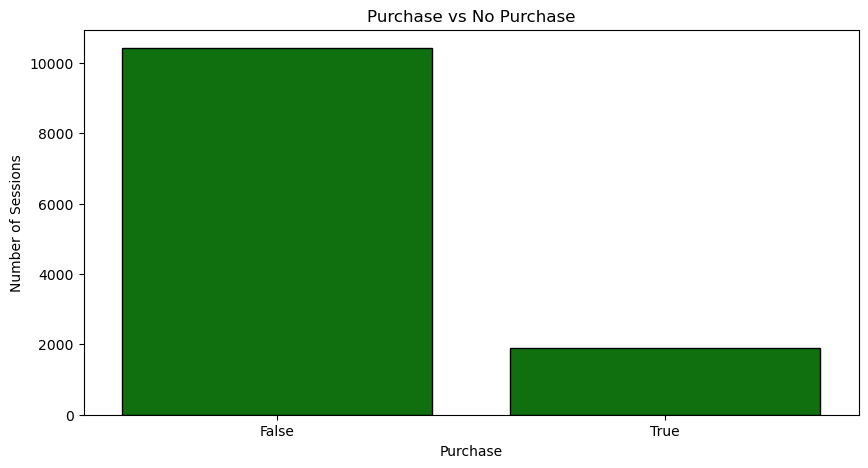

In [53]:
#  Revenue has two possible outcomes: purchase or no purchase.
plt.figure(figsize=(10, 5))

sns.countplot(data=df, x="Revenue",color='Green', edgecolor='Black') 
plt.title("Purchase vs No Purchase")
plt.xlabel("Purchase")
plt.ylabel("Number of Sessions")
plt.show()

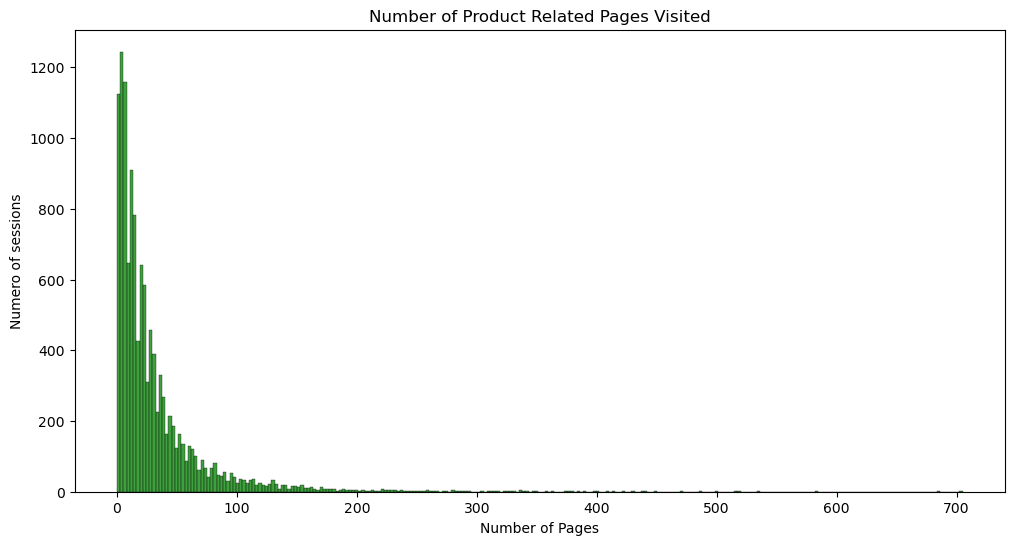

In [56]:
# Plot the original Product Related Visited
plt.figure(figsize=(12,6))

sns.histplot(df["ProductRelated"],color='Green', edgecolor='Black')
plt.title('Number of Product Related Pages Visited')
plt.xlabel('Number of Pages')
plt.ylabel('Numero of sessions')

plt.show()

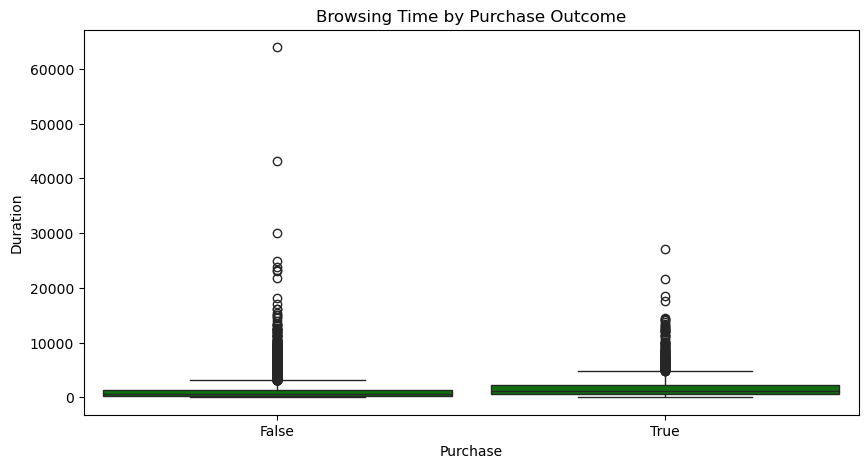

In [43]:
# Plot the boxplot Browsing time and purchases 
plt.figure(figsize=(10, 5))
sns.boxplot (data=df, x="Revenue", y="ProductRelated_Duration",color='Green', width=0.9 ,linewidth=1)
plt.title ("Browsing Time by Purchase Outcome")
plt.xlabel("Purchase")
plt.ylabel("Duration")
plt.show()

Probability of purchase: 0.15474452554744525


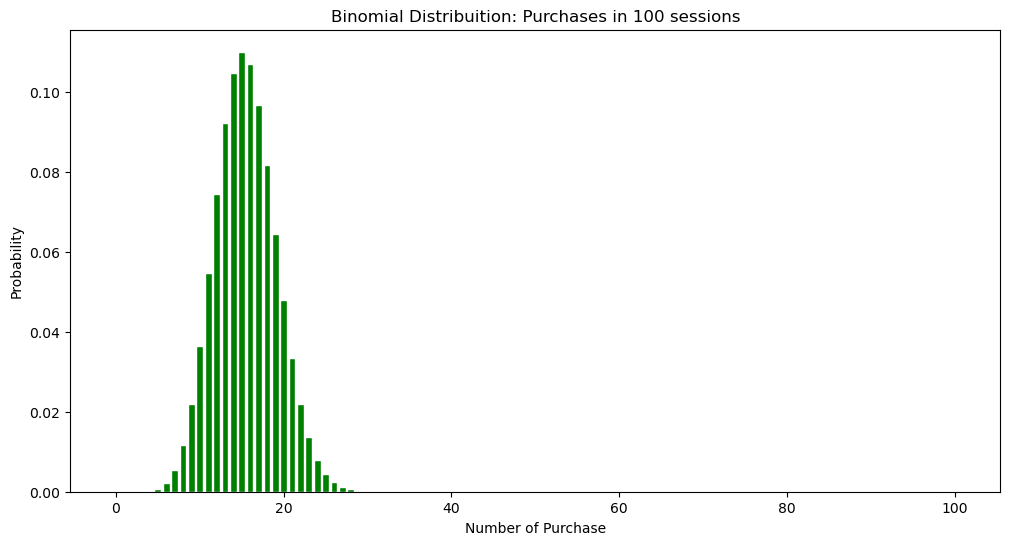

In [60]:
# The Binomial distribution models the number of purchases
number_of_purchase = (df["Revenue"] == True).sum()
total_sessions = len(df)
p= number_of_purchase / total_sessions

# Number of the sessions to analyse
n = 100   

# Expected number of purchases
print("Probability of purchase:", p)

# Plot the Binomial Distribuition - Probability

x = np.arange (0, n + 1)
probabilities = binom.pmf (x, n, p)

plt.figure(figsize=(12,6))
plt.bar(x, probabilities, color='Green', edgecolor='white')
plt.title("Binomial Distribuition: Purchases in 100 sessions")
plt.xlabel("Number of Purchase") 
plt.ylabel("Probability")

plt.show()      

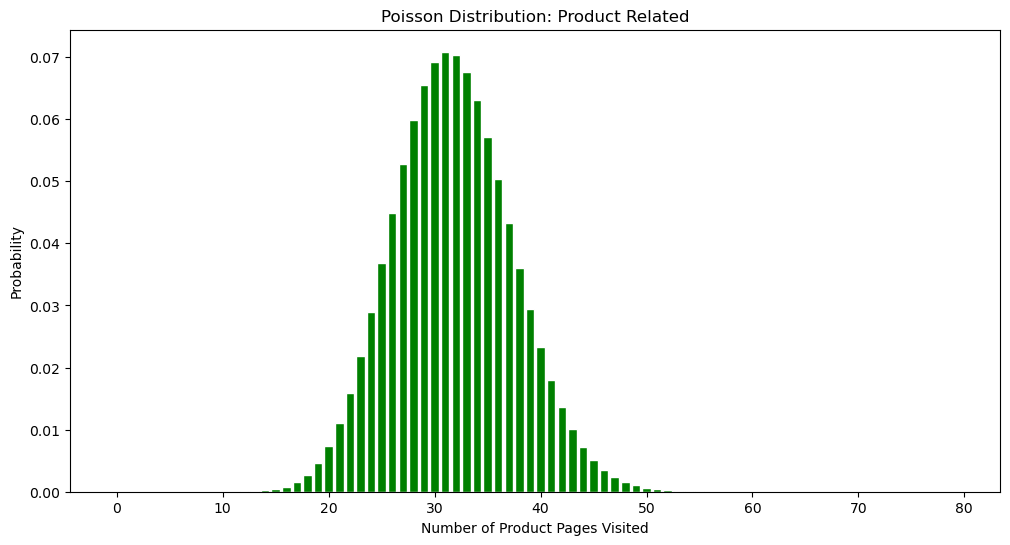

In [61]:
# Parameters Poisson Graph
lambda_value = df["ProductRelated"].mean()
x = np.arange(0, 80)

# Poisson probability mass function (pmf)
poisson_pmf = poisson.pmf(x, lambda_value)

# Plot the Poisson distribution
plt.figure(figsize=(12, 6))
plt.bar(x, poisson_pmf, color="green", edgecolor="white")
plt.title("Poisson Distribution: Product Related")
plt.xlabel("Number of Product Pages Visited")
plt.ylabel("Probability")
plt.show()

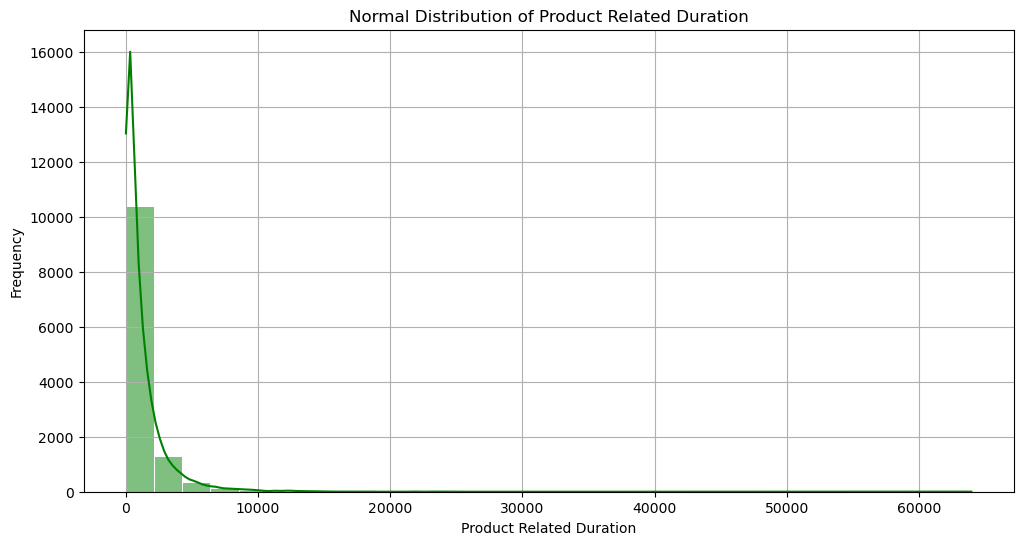

In [62]:
# Plot Normal Distribution Product Related Duration

plt.figure(figsize=(12, 6))

sns.histplot(df["ProductRelated_Duration"], bins=30, kde=True,color="green",
    edgecolor="white",linewidth=0.7)

plt.title("Normal Distribution of Product Related Duration")
plt.xlabel("Product Related Duration")
plt.ylabel("Frequency")
plt.grid()

plt.show()
